# 06 · Defect pattern → yield: which pattern costs the most?

**Question:** a wafer map already shows its yield, so the useful question is not *how much* yield was lost but *why*. Each defect pattern points to a different root cause (tool, process step, handling), so attributing lost yield to patterns tells engineers which problem to fix first.

**Method**
- *Baseline loss*: the mean yield of `none` wafers (training split). Every wafer loses this much anyway; a pattern's cost is the loss **beyond** it.
- *Excess loss* per pattern = frequency × severity, in **wafer-equivalents** (a wafer 10 points below baseline counts as 0.10 wafers lost).
- *Chained use*: on new wafers there is no label, so the pattern comes from the classifier. Section 4 checks whether loss attributed with **predicted** patterns matches the loss attributed with true labels on the test split.

In [1]:
%matplotlib inline
import json
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from wafer import evaluate
from wafer import yield_analysis as ya
from wafer.data import FAILURE_TYPES
from wafer.features import extract_features
from wafer.preprocess import load_dataset

FIG_DIR = Path('../reports/figures'); FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.precision', 3)

ds = load_dataset()
names = np.array(FAILURE_TYPES)[ds['y']]
tr, va, te = (ds['split'] == s for s in ('train', 'val', 'test'))
BASE = ya.baseline_yield(ds['y'][tr], ds['die_yield'][tr])
print(f'baseline (none) yield: {BASE:.3f}')

baseline (none) yield: 0.894


## 1. Severity vs frequency

In [2]:
table = ya.yield_loss_table(ds['y'], ds['die_yield'], BASE)
table

,wafers,mean_yield,excess_per_wafer,excess_wafers,share,gain_if_fixed_pts
pattern,,,,,,
Center,4294,0.768,0.127,544.328,0.262,0.315
Edge-Ring,9680,0.849,0.046,441.163,0.212,0.255
Edge-Loc,5189,0.817,0.077,400.161,0.192,0.231
Random,866,0.519,0.375,324.651,0.156,0.188
Loc,3593,0.850,0.044,158.891,0.076,0.092
Near-full,149,0.123,0.771,114.905,0.055,0.066
Donut,555,0.723,0.171,94.964,0.046,0.055
Scratch,1193,0.899,-0.005,-6.142,0.000,0.000


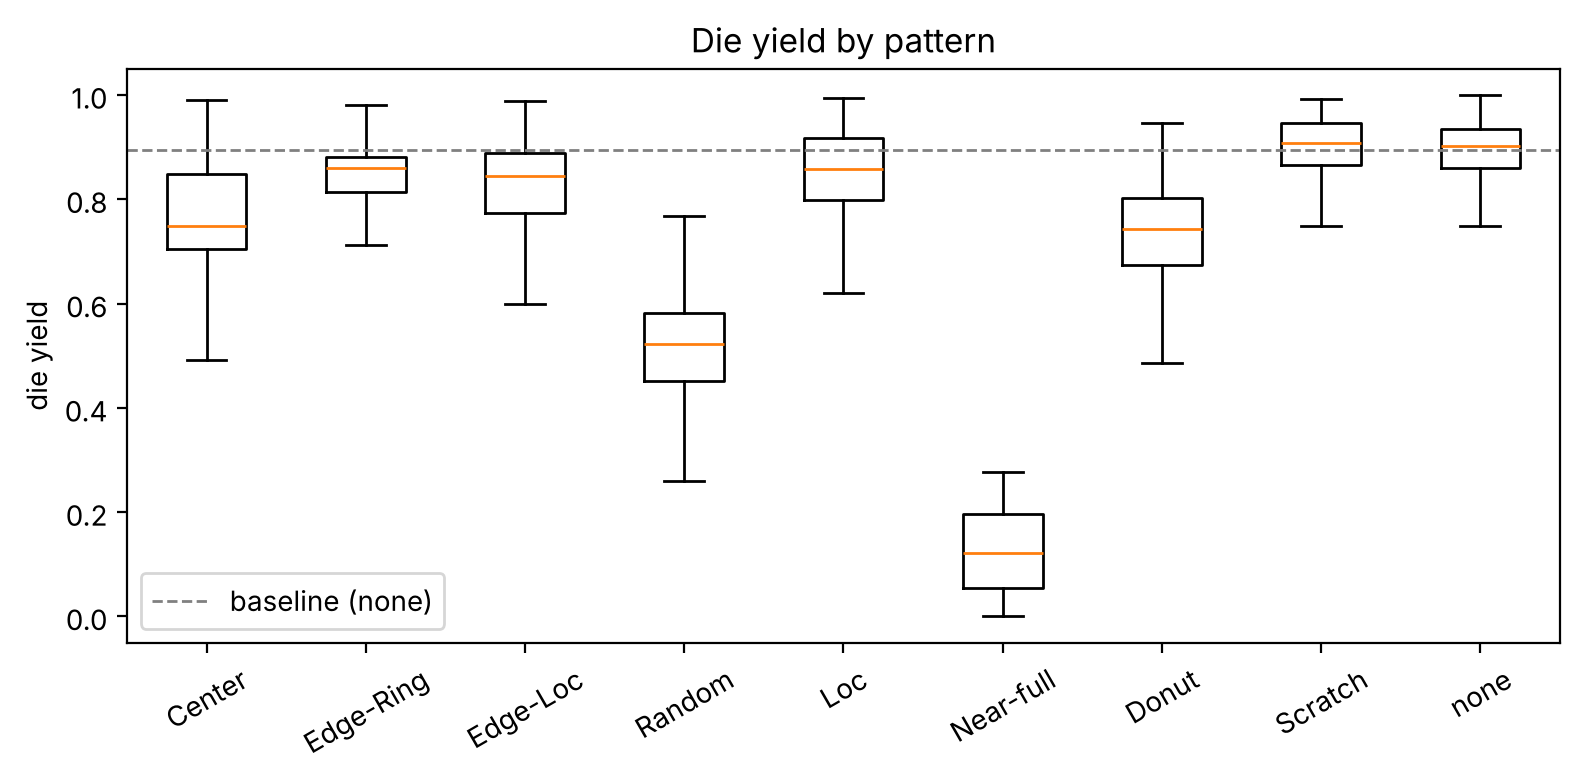

In [3]:
order = table.index.tolist() + ['none']
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([ds['die_yield'][names == p] for p in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=30)
ax.axhline(BASE, color='grey', ls='--', lw=1, label='baseline (none)')
ax.set_ylabel('die yield'); ax.legend(); ax.set_title('Die yield by pattern')
plt.tight_layout(); plt.savefig(FIG_DIR / 'yield_box_by_pattern.png', dpi=150)

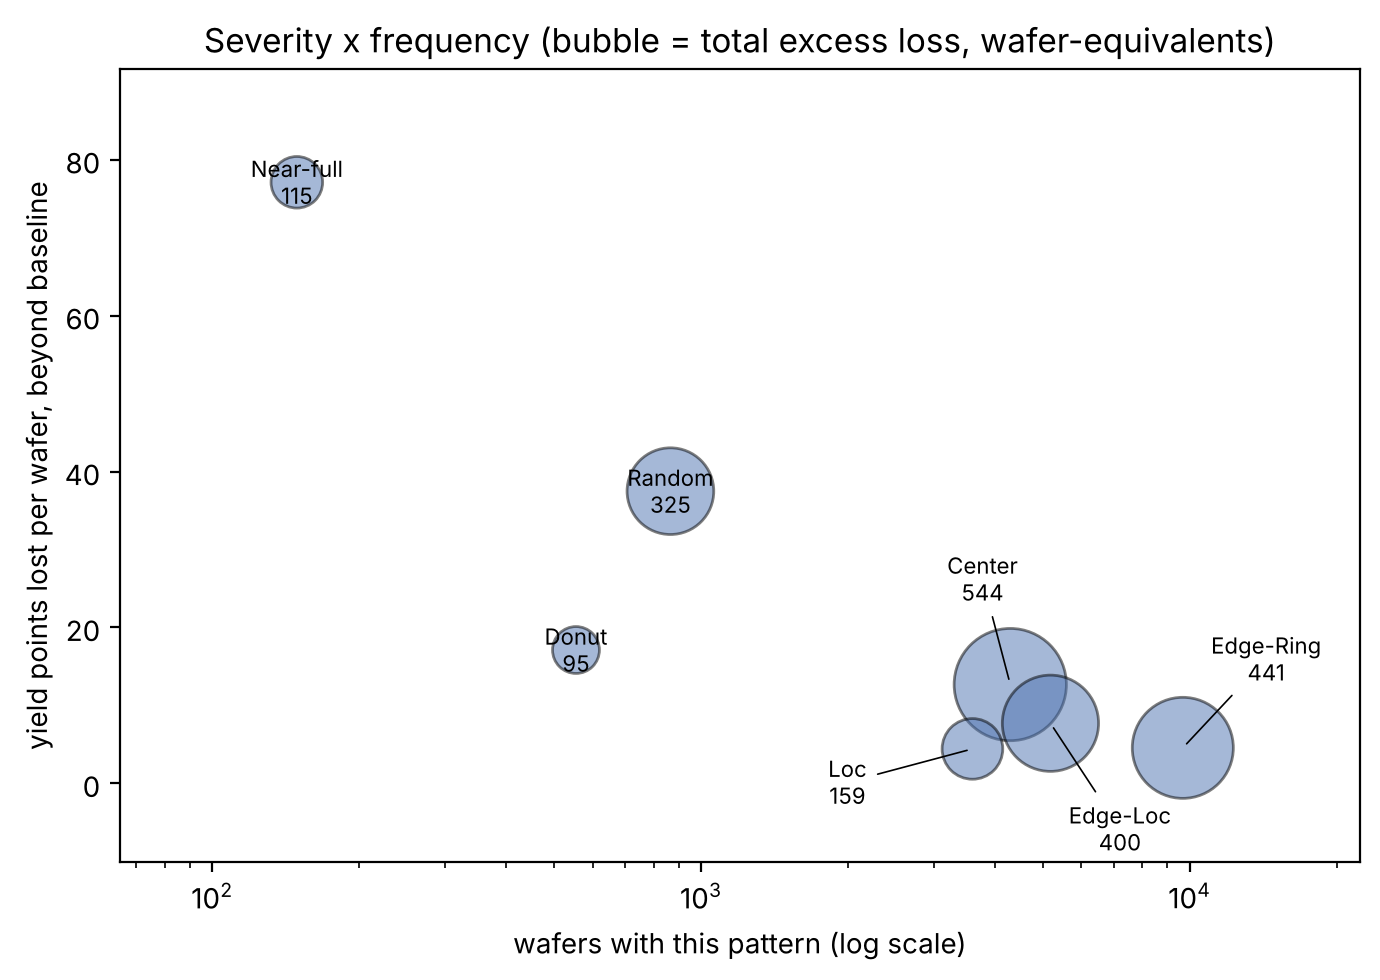

In [4]:
t = table[table['excess_wafers'] > 0]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(t['wafers'], t['excess_per_wafer'] * 100, s=t['excess_wafers'] * 3,
           alpha=0.5, color='#4C72B0', edgecolor='k')
# label offsets (points) so the crowded bubbles on the right stay readable
offset = {'Center': (-10, 38), 'Edge-Loc': (25, -38), 'Loc': (-45, -12),
          'Edge-Ring': (30, 32)}
for p, r in t.iterrows():
    dx, dy = offset.get(p, (0, 0))
    ax.annotate(f"{p}\n{r['excess_wafers']:.0f}",
                (r['wafers'], r['excess_per_wafer'] * 100),
                xytext=(dx, dy), textcoords='offset points',
                ha='center', va='center', fontsize=8,
                arrowprops=dict(arrowstyle='-', lw=0.6) if dx or dy else None)
ax.set_xscale('log'); ax.set_xlabel('wafers with this pattern (log scale)')
ax.set_ylabel('yield points lost per wafer, beyond baseline')
ax.set_title('Severity x frequency (bubble = total excess loss, wafer-equivalents)')
ax.margins(0.2); plt.tight_layout()
plt.savefig(FIG_DIR / 'yield_severity_frequency.png', dpi=150)

## 2. Pareto: where does pattern-caused loss go?

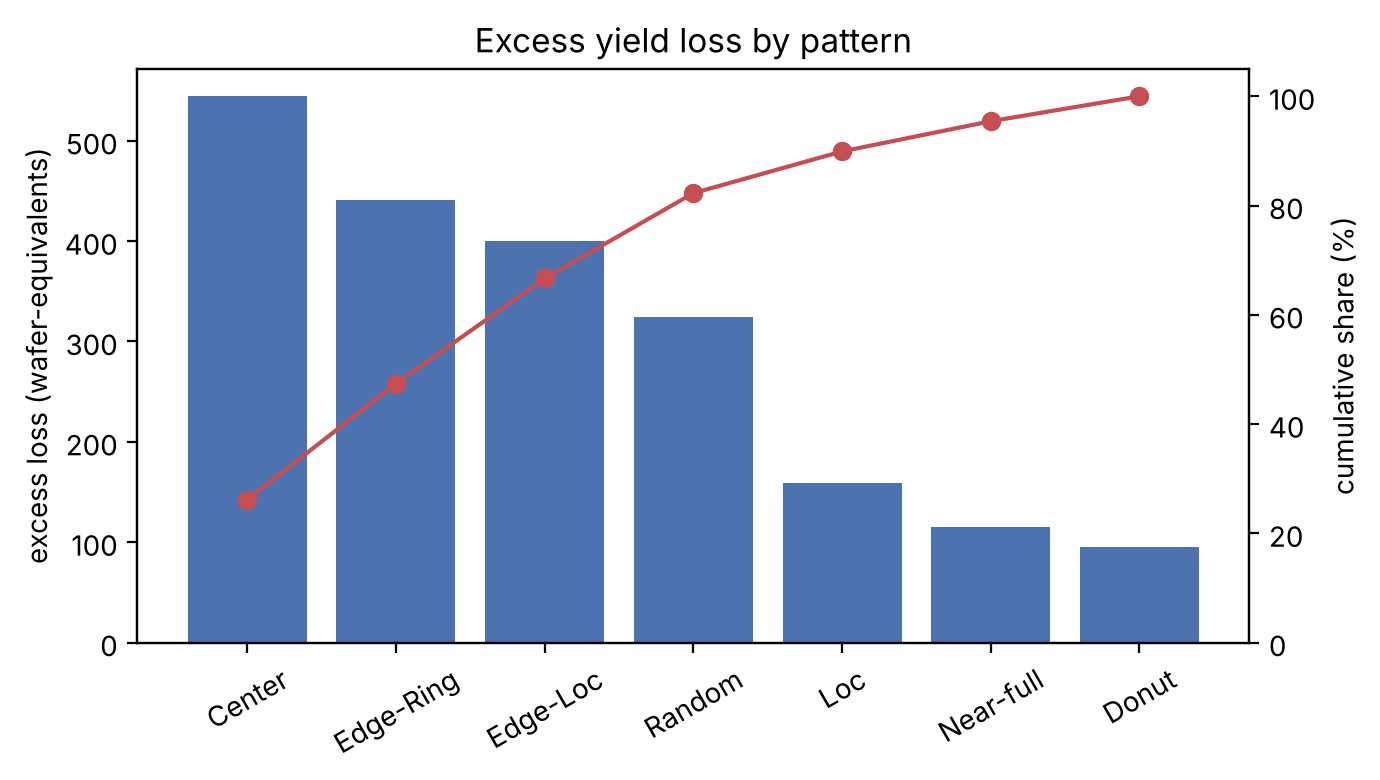

In [5]:
ax = ya.plot_pareto(table)
plt.savefig(FIG_DIR / 'yield_pareto.png', dpi=150)

## 3. How much of all lost yield do patterns explain?

In [6]:
total_loss = (1 - ds['die_yield']).sum()
pattern_excess = table['excess_wafers'].clip(lower=0).sum()
print(f'total loss: {total_loss:,.0f} wafer-equivalents')
print(f'excess loss caused by patterns: {pattern_excess:,.0f} '
      f'({pattern_excess / total_loss:.1%} of all loss)')

total loss: 20,344 wafer-equivalents
excess loss caused by patterns: 2,079 (10.2% of all loss)


## 4. Chained: attribute loss with the classifier's predictions

Same LightGBM baseline as notebook 03, trained on the training split. On the test split, compare the loss attributed to each pattern using predicted vs true labels.

In [7]:
%%time
F = extract_features(ds['X'])
clf = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=63,
    class_weight='balanced', subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, verbose=-1,
)
# eval_set works on every LightGBM 4.x; newer versions only warn that it is renamed
warnings.filterwarnings('ignore', message='.*eval_set.*')
clf.fit(F[tr], ds['y'][tr], eval_set=[(F[va], ds['y'][va])],
        callbacks=[lgb.early_stopping(100, verbose=False)])
pred = clf.predict(F[te])
evaluate.summarize(ds['y'][te], pred, ds['n_fail'][te], name='LightGBM')

CPU times: user 2min 21s, sys: 8.93 s, total: 2min 30s
Wall time: 1min 15s


macro_f1              0.860
weighted_f1           0.967
accuracy              0.966
yield_loss_capture    0.922
Name: LightGBM, dtype: float64

In [8]:
attr = ya.attribution_error(ds['y'][te], pred, ds['die_yield'][te], BASE)
attr

,true,predicted,error_pct
pattern,,,
Center,107.500,110.555,0.028
Edge-Ring,84.722,85.229,0.006
Edge-Loc,70.568,76.043,0.078
Random,66.949,62.686,-0.064
Loc,36.107,41.716,0.155
Near-full,23.786,25.673,0.079
Donut,17.891,16.760,-0.063
Scratch,-2.246,-2.550,-0.135


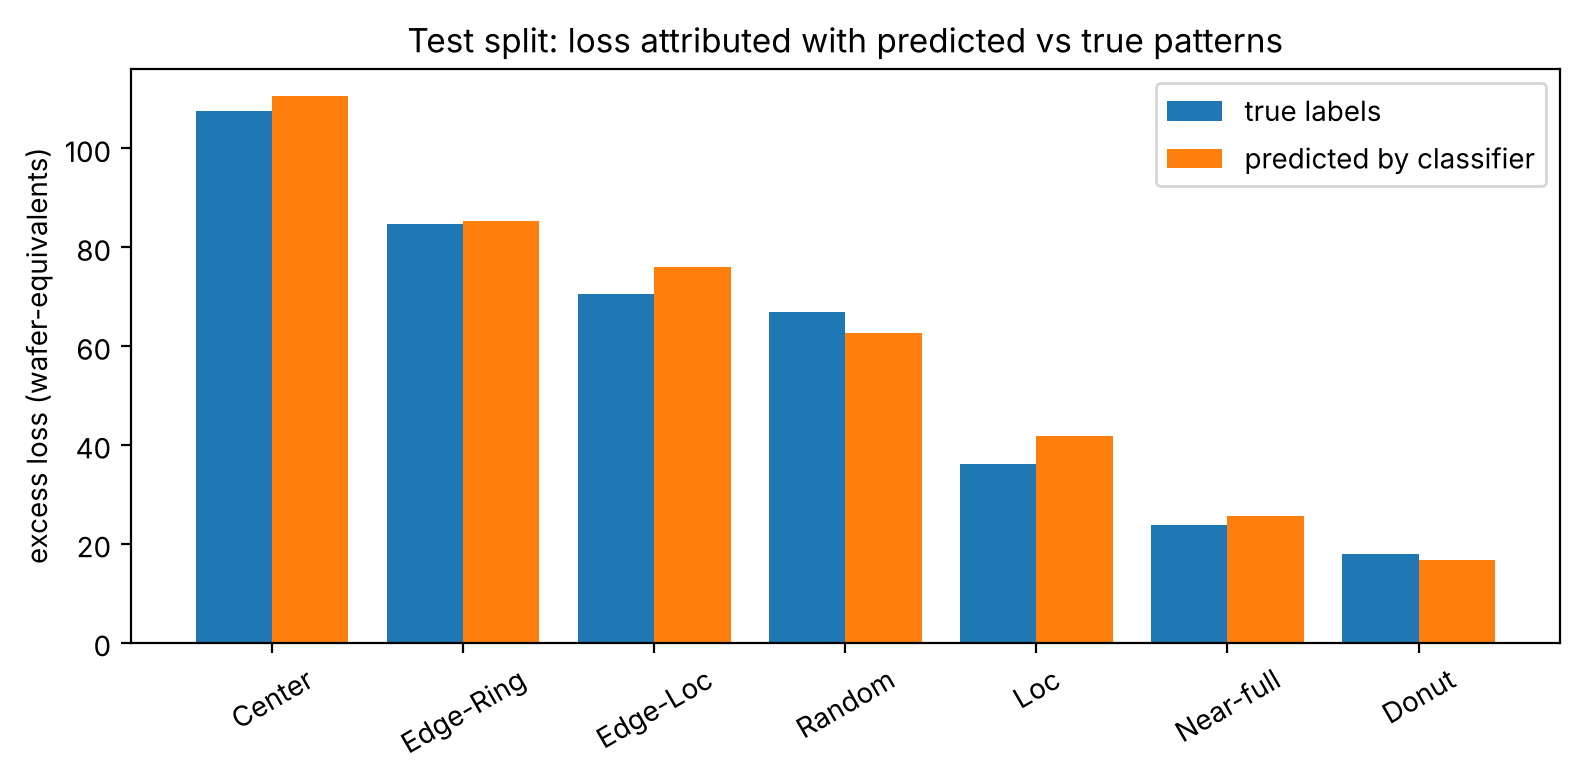

In [9]:
a = attr[attr['true'] > 0]
x = np.arange(len(a)); w = 0.4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - w / 2, a['true'], w, label='true labels')
ax.bar(x + w / 2, a['predicted'], w, label='predicted by classifier')
ax.set_xticks(x, a.index, rotation=30)
ax.set_ylabel('excess loss (wafer-equivalents)')
ax.set_title('Test split: loss attributed with predicted vs true patterns')
ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / 'yield_attribution_test.png', dpi=150)

In [10]:
same_rank = list(attr.index[:3]) == list(attr.sort_values('predicted', ascending=False).index[:3])
print('top-3 priority order identical with predicted labels:', same_rank)

top-3 priority order identical with predicted labels: True


## 5. Save results for the README and the app

In [11]:
results = {
    'baseline_yield': round(BASE, 4),
    'pattern_share_of_all_loss': round(float(pattern_excess / total_loss), 4),
    'table': table.round(4).reset_index().to_dict(orient='records'),
    'test_attribution': attr.round(3).reset_index().to_dict(orient='records'),
}
Path('../reports/results_yield.json').write_text(json.dumps(results, indent=2))
table.round(3)

,wafers,mean_yield,excess_per_wafer,excess_wafers,share,gain_if_fixed_pts
pattern,,,,,,
Center,4294,0.768,0.127,544.328,0.262,0.315
Edge-Ring,9680,0.849,0.046,441.163,0.212,0.255
Edge-Loc,5189,0.817,0.077,400.161,0.192,0.231
Random,866,0.519,0.375,324.651,0.156,0.188
Loc,3593,0.850,0.044,158.891,0.076,0.092
Near-full,149,0.123,0.771,114.905,0.055,0.066
Donut,555,0.723,0.171,94.964,0.046,0.055
Scratch,1193,0.899,-0.005,-6.142,0.000,0.000


## Findings

**Question.** A wafer map already shows its yield, so the useful question is *why* the dies were
lost. Each defect pattern points to a different root cause, so attributing lost yield to patterns
tells engineers which problem to fix first.

**Method.** Pattern-free (`none`) wafers average **89.4%** die yield (training split). That is
the loss every wafer has anyway. A pattern's cost is the loss *beyond* it, summed over its wafers
in wafer-equivalents (a wafer 10 points below baseline counts as 0.10 wafers lost).

| Pattern | Wafers | Mean yield | Points lost per wafer | Total excess loss | Share |
|---|---|---|---|---|---|
| Center | 4,294 | 77% | 13 | 544 | 26% |
| Edge-Ring | 9,680 | 85% | 5 | 441 | 21% |
| Edge-Loc | 5,189 | 82% | 8 | 400 | 19% |
| Random | 866 | 52% | 37 | 325 | 16% |
| Loc | 3,593 | 85% | 4 | 159 | 8% |
| Near-full | 149 | 12% | 77 | 115 | 6% |
| Donut | 555 | 72% | 17 | 95 | 5% |
| Scratch | 1,193 | 90% | −1 | −6 | 0% |

1. **Severity is not priority.** `Near-full` is the most severe pattern (wafers are nearly
   scrapped) but ranks 6th by total loss because it is rare. Three frequent, mild patterns
   (`Center`, `Edge-Ring`, `Edge-Loc`) cause **67%** of pattern-caused loss. Ranking defects by
   how bad one wafer looks would send engineers to the wrong problem.
2. **`Center` is the first problem to fix.** It ranks first because it is both fairly common
   and fairly severe (13 points per wafer). Bringing those wafers back to baseline would raise
   the yield of the whole labeled set by about 0.3 points.
3. **`Scratch` costs no measurable yield.** Its wafers yield as well as pattern-free ones.
   A scratch can still flag a handling problem, but not a yield one.
4. **Patterns explain only about 10% of all lost yield.** The other 90% is the baseline loss
   spread across every wafer. Pattern classification is a tool for the systematic part.
   The random part needs process data, as in the SECOM analysis.
5. **The classifier is good enough for this use.** On the test split, loss attributed with the
   LightGBM model's *predicted* patterns is within 8% of the true attribution for every pattern
   that costs yield, except `Loc` (+16%: 205 test wafers labeled `none` are called `Loc`, and
   they carry some extra loss). The top-3 priority order is identical, so the chain also works
   on new, unlabeled wafers.

**Limitations.** Only the labeled 21% of WM-811K is used, and labeled wafers may not reflect the
fab's real production mix. Wafer-equivalents weight every wafer equally, whatever its die
count. The suspected causes shown in the demo are common explanations from the literature, not a
diagnosis.
